# Comparative Reliability Performance of N-Body Simulation under Hamiltonian Framework Applying Barnes-Hut Trees
Within the realms of modern orbital mechanics application of Barnes-Hut trees is a common practice for large N-Body simulations. The project describes the creation of a C++ and R tool to simulate the problem assessing reliability of the Barnes-Hut trees for cosmological applications via application of symplectic and non-symplectic integration schemes.

## About The Notebook
This notebook is a simulation prototype, that shows fast results and validation of said results using Python.
It will be kept in a dated entry order expanding each individual feature for a later transfer to C++ and R framework.
It will also comply with the project's gantt chart of progress.

Please bear in mind that the function and variable names follow a certain pattern:
- Integrators and their daughter functions: `operation_integrator_order`
- Mathematical equations take their literal mathematical names, where numerator is a numerator, product is a product, etc.

## Setting the Environment and Creating Velocity Verlet 4th Order

In [1]:
# Imports
import matplotlib.pyplot as plt
import numpy as np
import random as rnd

# Randomisation Seed
seed = 256
rnd.seed(seed)

# Constants
yoshida_x0 = -(2**(1/3))/(2-(2**(1/3)))
yoshida_x1 = (1/(2-(2**(1/3))))

In [2]:
"""
Creating helper functions to help with force evaluation later.
"""

# Find Euclidian distance between two bodies
# obj_a – object i with accessible properties
# obj_b - object j with accessible properties
def euclidian_distance(obj_a, obj_b):
    return np.linalg.norm(obj_a.r - obj_b.r)

# Find initial velocity
# obj – individual object with accessible properties
# G – constant of gravitational attraction
# distance – previously found Euclidian distance
def vel_init(obj, G, distance):
    return rnd.random() * np.sqrt((G*obj.m) / distance)  # random variable in the beginning is used to create random orbit eccentricities (no ejection)

# Get a perpendicular vector
def get_perpendicular(v):
    x, y, z = v
    if x != 0 or y != 0:
        perp = np.array([-y, x, 0.0], dtype=float)
    else:
        perp = np.array([0.0, 1.0, 0.0], dtype=float)

    return perp

# Find velocity direction
# Essentially convert scalar velocity into vector velocity
# obj_a – object i with accessible properties
# obj_b - object j with accessible properties
# v – scalar velocity
def vel_direction(obj_a, obj_b, v):
    radius_vector = obj_b.r - obj_a.r
    perp_vector = get_perpendicular(radius_vector)
    unit_perp_vector = perp_vector / np.linalg.norm(perp_vector)    # normalise by its own length

    return v * unit_perp_vector


# Compute Gravitational Acceleration of All Bodies acting on i
# G – the constant of gravitational attraction
# bod_obj – a list of stellar bodies represented as objects.
#           Contains objects themselves. Allows to access
#           individual parameters such as: mass, initial velocity,
#           and initial displacement.
# e – softening factor to prevent division by 0 errors in case
#     the bodies get too close.
def acc(G, bod_obj, e):
    N = len(bod_obj)    
    accelerations = [np.zeros(3) for _ in range(N)]     # initialise an array to hold acceleration vectors for all bodies

    # Sigma operation
    # Loop over every body i
    for i in range(N):
        a_i = np.zeros(3)   # net acceleration vector on body i

        # Sum gravitational pull from every other body j
        for j in range(N):
            if i == j:
                continue    # idiot-proofing self-interaction

            # Compute displacement from i to j
            r_ij = bod_obj[i].r - bod_obj[j].r

            # Scalar distance squared
            dist_sq = np.sum(r_ij**2)

            # Denominator with softening factor
            denominator = (dist_sq + e**2)**1.5

            # Add the j-body contribution
            a_i += bod_obj[j].m * (r_ij / denominator)

        # Apply -G and store the net acceleration for body i
        accelerations[i] = -G * a_i

    return accelerations


In [3]:
"""
Conservation Value Calculations

This cell contains all the functions to help with the conservation and will be further embedded into the code.
Here, we will define later-mentioned Hamiltonian and momenta conservations, as well as their relative values.
"""

# Calculate the kinetic energy of the system: T = sum_i |p_i|^2 / (2 m_i)
# bod_obj – a list of stellar bodies represented as objects.
#           Contains objects themselves. Allows to access
#           individual parameters such as: mass, initial velocity,
#           and initial displacement.
def t_abs(bod_obj):
    t = 0.0     # total kinetic energy
    # Iterate through the list of bodies to extract individual values for the velocity and mass
    for obj in bod_obj:
        p = obj.m * obj.v       # linear momentum vector of the body
        t += np.dot(p, p) / (2 * obj.m)     # |p|^2 is a dot product, so that the result is a scalar

    return t

# Calculate the (softened) gravitational potential energy of the system:
# V = -G * sum_{i<j} m_i m_j / sqrt(|r_i - r_j|^2 + e^2)
# bod_obj – a list of stellar bodies represented as objects.
# G – the constant of gravitational attraction
# e – softening factor (it has to be the same one as in acc, otherwise H is not the
#     energy that the integrator is actually conserving)
def v_abs(bod_obj, G, e):
    N = len(bod_obj)

    v_tot = 0.0     # potential energy total (without the -G factor)

    # Sum over every UNIQUE pair (i < j): a pair holds one potential energy, not two
    for i in range(N):
        for j in range(i + 1, N):
            r_ij = bod_obj[i].r - bod_obj[j].r      # separation vector
            numerator = bod_obj[i].m * bod_obj[j].m
            denominator = np.sqrt(np.dot(r_ij, r_ij) + e**2)    # |r_ij|^2 is a scalar (dot product)

            v_tot += numerator / denominator

    return -G * v_tot

# Calculate the absolute Hamiltonian value
# t – system's kinetic energy (calculated previously)
# v – system's potential energy (calculated previously)
def h_abs(t, v):
    return t + v

# Convert the Hamiltonian into a relative energy error
# h_0 – initial Hamiltonian value at the start of the simulation clock
# h_n – current Hamiltonian value at the given moment in time
def h_rel(h_0, h_n):
    return abs(h_n - h_0) / abs(h_0)

# Calculate absolute linear momentum: P = sum_i m_i v_i  (a 3-vector)
# bod_obj – a list of stellar bodies represented as objects.
def p_abs(bod_obj):
    p_total = np.zeros(3)   # initiate a total linear momentum vector

    # Iterate over every single object in the system
    for obj in bod_obj:
        p_total += obj.m * obj.v

    return p_total

# Characteristic linear momentum of the system: sum_i |m_i v_i|
# Used as the reference when the total momentum is (close to) zero.
def p_scale(bod_obj):
    return sum(obj.m * np.linalg.norm(obj.v) for obj in bod_obj)

# Calculate the Total Relative Linear Momentum Error
# p_0 – initial linear momentum vector at the start of the simulation
# p_n – current linear momentum vector at the time of the reading
# scale – characteristic momentum (p_scale at t = 0), used instead of |p_0| if |p_0| ~ 0
def p_rel(p_0, p_n, scale):
    reference = np.linalg.norm(p_0)
    if reference < 1e-12 * scale:       # P_0 = 0: relative error is undefined, use the scale
        reference = scale

    return np.linalg.norm(p_n - p_0) / reference

# Calculate Total Angular Momentum: L = sum_i m_i (r_i x v_i)  (a 3-vector)
# bod_obj – a list of stellar bodies represented as objects.
def l_abs(bod_obj):
    l_tot = np.zeros(3)     # initiate the summation vector of the total angular momentum

    # Iterate over every body in the system
    for obj in bod_obj:
        l_tot += obj.m * np.cross(obj.r, obj.v)     # cross product, NOT an element-wise product

    return l_tot

# Characteristic angular momentum of the system: sum_i |m_i (r_i x v_i)|
def l_scale(bod_obj):
    return sum(obj.m * np.linalg.norm(np.cross(obj.r, obj.v)) for obj in bod_obj)

# Calculate the Total Relative Angular Momentum Error
# l_0 – initial angular momentum vector at the start of the simulation
# l_n – current angular momentum vector
# scale – characteristic angular momentum (l_scale at t = 0), used instead of |l_0| if |l_0| ~ 0
def l_rel(l_0, l_n, scale):
    reference = np.linalg.norm(l_0)
    if reference < 1e-12 * scale:       # L_0 = 0: relative error is undefined, use the scale
        reference = scale

    return np.linalg.norm(l_n - l_0) / reference

# Snapshot of all conserved quantities at one instant: returns (H, P, L)
def conservation_state(bod_obj, G, e):
    return h_abs(t_abs(bod_obj), v_abs(bod_obj, G, e)), p_abs(bod_obj), l_abs(bod_obj)

In [4]:
"""
Creating a Velocity Verlet 4th Order Script.
It consists of the acceleration, displacement and velocity computations.

The detailed description of the algorithm will be provided later down below.
"""

# Compute Displacement of an individual body
# obj – individual object with accessible properties
# t – current timestep
def displ_vv_4(obj, t):
    return obj.r + obj.v*t + (0.5*obj.a*(t**2))

# Compute Velocity of an individual body
# obj – individual object with accessible properties
# t – current timestep
# a_old – old acceleration of the body
def vel_vv_4(obj, t, a_old):
    return obj.v + 0.5*(a_old+obj.a)*t

# Run Velocity Verlet (4th order, Yoshida composition of three 2nd order steps)
# bod_obj – a list of stellar bodies represented as objects.
#           Contains objects themselves. Allows to access
#           individual parameters such as: mass, initial velocity,
#           and initial displacement.
# G – the constant of gravitational attraction
# e – softening factor to prevent division by 0 errors in case
#     the bodies get too close.
# dt – timestep of the simulation
# n_steps – number of timesteps to take
# NB: the initial conditions (r, v, m) must be set on every body before calling this.
def run_vv_4(bod_obj, G, e, dt, n_steps):
    weights = (yoshida_x1, yoshida_x0, yoshida_x1)    # sub-step sizes as fractions of dt (they sum to 1)

    # Initial accelerations of all bodies
    for obj, a in zip(bod_obj, acc(G, bod_obj, e)):
        obj.a = a

    # Start the clock of the simulated Universe
    for _ in range(n_steps):
        # Yoshida sub-steps: each one is a full Velocity Verlet step of size w*dt
        for w in weights:
            h = w * dt

            a_old = [obj.a for obj in bod_obj]    # accelerations before the move

            # Move ALL bodies first (new displacement)
            for obj in bod_obj:
                obj.r = displ_vv_4(obj, h)

            # Re-evaluate the forces once for the whole system (new acceleration)
            for obj, a in zip(bod_obj, acc(G, bod_obj, e)):
                obj.a = a

            # Update ALL velocities with the average of old and new acceleration
            for obj, a_prev in zip(bod_obj, a_old):
                obj.v = vel_vv_4(obj, h, a_prev)


## Velocity Verlet 4th Order Explanation
In order to solve the N-body problem numerically, several quantities have to be evaluated: the Euclidean distance between pairs of bodies, an initial velocity vector obtained from a randomised scalar speed, and the gravitational acceleration, which is then propagated in time by the integrator. The initial speed is scaled by a random factor in order to produce a variety of orbital eccentricities for experimental purposes.

**Notation.** Bodies are indexed by $i, j = 1, \dots, N$. Vectors carry a hat in the convention used throughout this notebook: $\hat{r}_i$ is the displacement, $\hat{v}_i$ the velocity and $\hat{a}_i$ the acceleration of body $i$, while $m_i$ is its mass. $G$ is the gravitational constant, $\delta{t}$ is the timestep, $\epsilon$ is the softening length (`e` in the code) and $\xi$ is the random eccentricity factor.

### Euclidean Distance in 3D
The separation of two bodies is the length of the difference of their displacement vectors (`euclidian_distance`):

$$r_{ij}=\lvert\hat{r}_i-\hat{r}_j\rvert=\sqrt{(x_i-x_j)^2 + (y_i - y_j)^2 + (z_i-z_j)^2}$$

### Initial Speed
The speed of a circular orbit at distance $r_{ij}$ around a body of mass $M$ is $v_c=\sqrt{GM/r_{ij}}$, where $M$ is the mass of the attracting body. The initial speed is a random fraction of it (`vel_init`):

$$v_0=\xi\sqrt{\frac{GM}{r_{ij}}},\qquad \xi\sim\mathcal{U}[0,1)$$

The velocity is launched perpendicular to the radius vector, so the launch point is an apsis of the resulting orbit. For $\xi<1$ the body starts at apocentre and follows an ellipse of eccentricity $e_{\mathrm{orb}}=1-\xi^2$, while $\xi\to1$ gives a circular orbit. Since the escape speed $\sqrt{2}\,v_c$ is never reached, no body is ejected at the start of the simulation.

### Initial Velocity Direction
The scalar speed is converted into a vector by choosing a direction perpendicular to the radius vector $\Delta\hat{r}=\hat{r}_j-\hat{r}_i=(\Delta x,\Delta y,\Delta z)$ (`get_perpendicular` and `vel_direction`):

$$\hat{p}=(-\Delta y,\ \Delta x,\ 0),\qquad \hat{n}=\frac{\hat{p}}{\lvert\hat{p}\rvert},\qquad \hat{v}_0=v_0\,\hat{n}$$

The vector $\hat{p}$ is perpendicular to $\Delta\hat{r}$ because $\hat{p}\cdot\Delta\hat{r}=-\Delta x\Delta y+\Delta y\Delta x=0$. If $\Delta x=\Delta y=0$ the construction degenerates, and $\hat{p}=(0,1,0)$ is used instead. As $\hat{n}$ lies in the $xy$-plane, the initial orbits are planar.

### Gravitational Acceleration
Newton's law of gravitation, summed over all other bodies, gives the acceleration of body $i$ (`acc`). A softening length $\epsilon$ is added to the denominator (Plummer softening) so that the force stays finite when two bodies approach each other:

$$\hat{a}_i=-G\sum_{j\neq i}\frac{m_j\,(\hat{r}_i-\hat{r}_j)}{\left(\lvert\hat{r}_i-\hat{r}_j\rvert^2+\epsilon^2\right)^{3/2}}$$

This direct summation requires $\mathcal{O}(N^2)$ pair evaluations per call, which is precisely the cost that the Barnes-Hut tree reduces to $\mathcal{O}(N\log N)$ in the later C++ implementation.

### Velocity Verlet (Second Order)
Since the algorithm is a 4th-order Velocity Verlet, it integrates with a different pattern to the regular Verlet.
Regular 2nd-order Velocity Verlet uses the evaluation in a following pattern:
- Set up initial conditions
- Evaluate displacement
- Evaluate acceleration
- Evaluate velocity

I coined a name for this method, RAV, due to $\hat{r}$ being displacement, $\hat{a}$ acceleration and $\hat{v}$ velocity. Velocity Verlet can be expressed via the following equations, where a single step is denoted $S_2(\delta{t})$:

**Displacement** (`displ_vv_4`)

$$\hat{r}(t+\delta{t}) = \hat{r}(t)+\hat{v}(t)\,\delta{t}+\frac{\hat{a}(t)\,\delta{t}^2}{2}$$

**Velocity** (`vel_vv_4`)

$$\hat{v}(t+\delta{t})=\hat{v}(t)+\frac{\hat{a}(t)+\hat{a}(t+\delta{t})}{2}\,\delta{t}$$

The new acceleration $\hat{a}(t+\delta{t})$ in Eq. (6) is evaluated from the new displacements of Eq. (5), which is why the order of the three operations cannot be changed. The scheme is time-reversible and symplectic, but only second-order accurate: its global error scales as $\mathcal{O}(\delta{t}^2)$.

### Yoshida Composition to 4th Order
Yoshida's method raises the order by composing three second-order steps of different sizes:

$$S_4(\delta{t})=S_2(w_1\delta{t})\circ S_2(w_0\delta{t})\circ S_2(w_1\delta{t})$$

$$w_1=\frac{1}{2-2^{1/3}}\approx 1.3512,\qquad w_0=-\frac{2^{1/3}}{2-2^{1/3}}\approx -1.7024$$

In the code these are `yoshida_x1` and `yoshida_x0`. The weights are fixed by two conditions: the sub-steps must add up to one full step, and the leading error term of $S_2$ must cancel,

$$2w_1+w_0=1,\qquad 2w_1^3+w_0^3=0$$

so that the local error falls from $\mathcal{O}(\delta{t}^3)$ to $\mathcal{O}(\delta{t}^5)$ and the global error to $\mathcal{O}(\delta{t}^4)$. The middle weight $w_0$ is negative, so the middle sub-step runs backwards in time, but the three sub-steps together advance the system by exactly $\delta{t}$, and the composition remains symplectic. The price is three force evaluations per timestep instead of one.

### One Integration Step in the Code
For each of the three sub-steps of size $h=w\,\delta{t}$ with $w\in\{w_1, w_0, w_1\}$ (`run_vv_4`):
1. Store the current accelerations $\hat{a}_{\mathrm{old}}$ of all bodies.
2. Move all bodies using Eq. (5) with $\delta{t}\to h$.
3. Re-evaluate the accelerations of all bodies with Eq. (4) at the new positions.
4. Update all velocities using Eq. (6) with $\delta{t}\to h$ and $\hat{a}_{\mathrm{old}}$.

All bodies are moved before any acceleration is recomputed, so that every force is evaluated for the same instant.

# Conservation Formulae
## Energy (Hamiltonian) Conservation

Energy conservation is a widely used metric to directly track and diagnose issues within the numerical integrators. Due to the nature of symplectic integrators, the energy error does not drift away steadily but oscillates in a bounded band around the true value, which is the signature of the symplectic property. Non-symplectic methods may show a short-term success, whereas after a larger number of iterations their energy error grows systematically.

### Absolute Energy Conservation
Kinetic energy $T$ is expressed via $$T=\sum^N_{i=1}\frac{|\hat{p}_i|^2}{2m_i}$$ while potential energy $V$ is a sum over every *unique* pair of bodies: $$V=-G\sum_{1\leq i < j \leq N} \frac{m_i m_j}{\sqrt{|\hat{r}_i - \hat{r}_j|^2 + \epsilon^2}}$$ where $\hat{p}_i = m_i \hat{v}_i$ and $|\hat{r}_i - \hat{r}_j|$ is the Euclidean distance between two bodies. The strict inequality $i<j$ matters: a pair holds a single potential energy, so summing over $i\neq j$ (or $i\leq j$) would double-count it (or include self-interaction). The softening length $\epsilon$ is the same as in the acceleration, since $\hat{a}_i=-\frac{1}{m_i}\nabla_{\hat{r}_i}V$ reproduces Eq. (4) exactly.

Hence a Hamiltonian $H$ can be derived:
$$
H(\hat{r}, \hat{p}) = T + V = \sum^N_{i=1}\frac{|\hat{p}_i|^2}{2m_i} - G\sum_{1\leq i < j \leq N} \frac{m_i m_j}{\sqrt{|\hat{r}_i - \hat{r}_j|^2 + \epsilon^2}}
$$

### Relative Energy Conservation $H_{rel}$
Relative energy is the main tracking tool for the energy conservation, since it normalises absolute values to fit a relative parameter. It is expressed like this:
$$
H_{rel} = \frac{|H_{n}-H_{0}|}{|H_{0}|}
$$

## Momentum Calculus
Momentum calculations for both Linear $\hat{P}$ and Angular $\hat{L}$ momenta are required, since the momenta have to stay constant alongside with the oscillating or near-constant energy. Meaning, deviations from the constant may indicate underlying issues with the integrators or the simulation loops. All of the higher-mentioned parameters allow us to track accuracy.

### Total Linear Momentum $\hat{P}$
Total linear momentum is simply the vector sum of individual linear momenta across all bodies and expressed like this:
$$
\hat{P}=\sum^N_{i=1}m_i\hat{v}_i
$$

It is a 3-vector, hence each component from $x$ to $z$ inclusively is summed separately.

### Relative Total Linear Momentum Conservation $P_{rel}$
Relative total linear momentum is one of the main tracking tools for the momenta conservation, since it normalises absolute values to fit a relative parameter. Since $\hat{P}$ is a vector, its *length* is used:
$$
P_{rel} = \frac{|\hat{P}_{n}-\hat{P}_{0}|}{|\hat{P}_{0}|}
$$

Systems that are set up in their centre-of-mass frame (such as the figure-eight of Experiment 1) have $\hat{P}_0=0$, for which the expression above is undefined. In that case the denominator is replaced by the characteristic momentum of the system, $\sum_i m_i|\hat{v}_i(0)|$, so that $P_{rel}$ remains the error relative to the size of the individual momenta.

### Angular Momentum $\hat{L}$
$$
\hat{L} = \sum^N_{i=1}m_i(\hat{r}_i\times\hat{v}_i)
$$

The angular momentum is the other part of the momenta conservation toolkit. It is a vector built from the **cross product** of displacement and velocity (not the product of their unit vectors, and not a component-wise product). Both linear and angular momenta are conserved by the exact dynamics, and for pairwise central forces a symplectic integrator preserves them to rounding error, which makes them a sharp test for coding mistakes in the force routine and the loop.

### Relative Angular Momentum Conservation Expression $L_{rel}$
As with the prior equations, the relative angular momentum error is computed via the length of the difference between the initial and current angular momenta, divided by the length of the initial one:

$$
L_{rel} = \frac{|\hat{L}_{n}-\hat{L}_{0}|}{|\hat{L}_{0}|}
$$

The figure-eight also has $\hat{L}_0=0$, so the denominator is again replaced by the characteristic value $\sum_i m_i|\hat{r}_i(0)\times\hat{v}_i(0)|$.

t_total = 18.9777 (3 periods), n_steps = 30000, dt = 6.326e-04
n_frames = 1500, steps_per_frame = 20
H_0 = -1.287142, |P_0| = 0.0e+00, |L_0| = 0.0e+00
body 1: closure error |r(T) - r(0)| = 5.920e-08
body 2: closure error |r(T) - r(0)| = 1.183e-07
body 3: closure error |r(T) - r(0)| = 5.906e-08
max |z| over the run = 0.000e+00 (the orbit is planar)
max H_rel = 1.599e-13, max P_rel = 8.563e-15, max L_rel = 2.717e-14


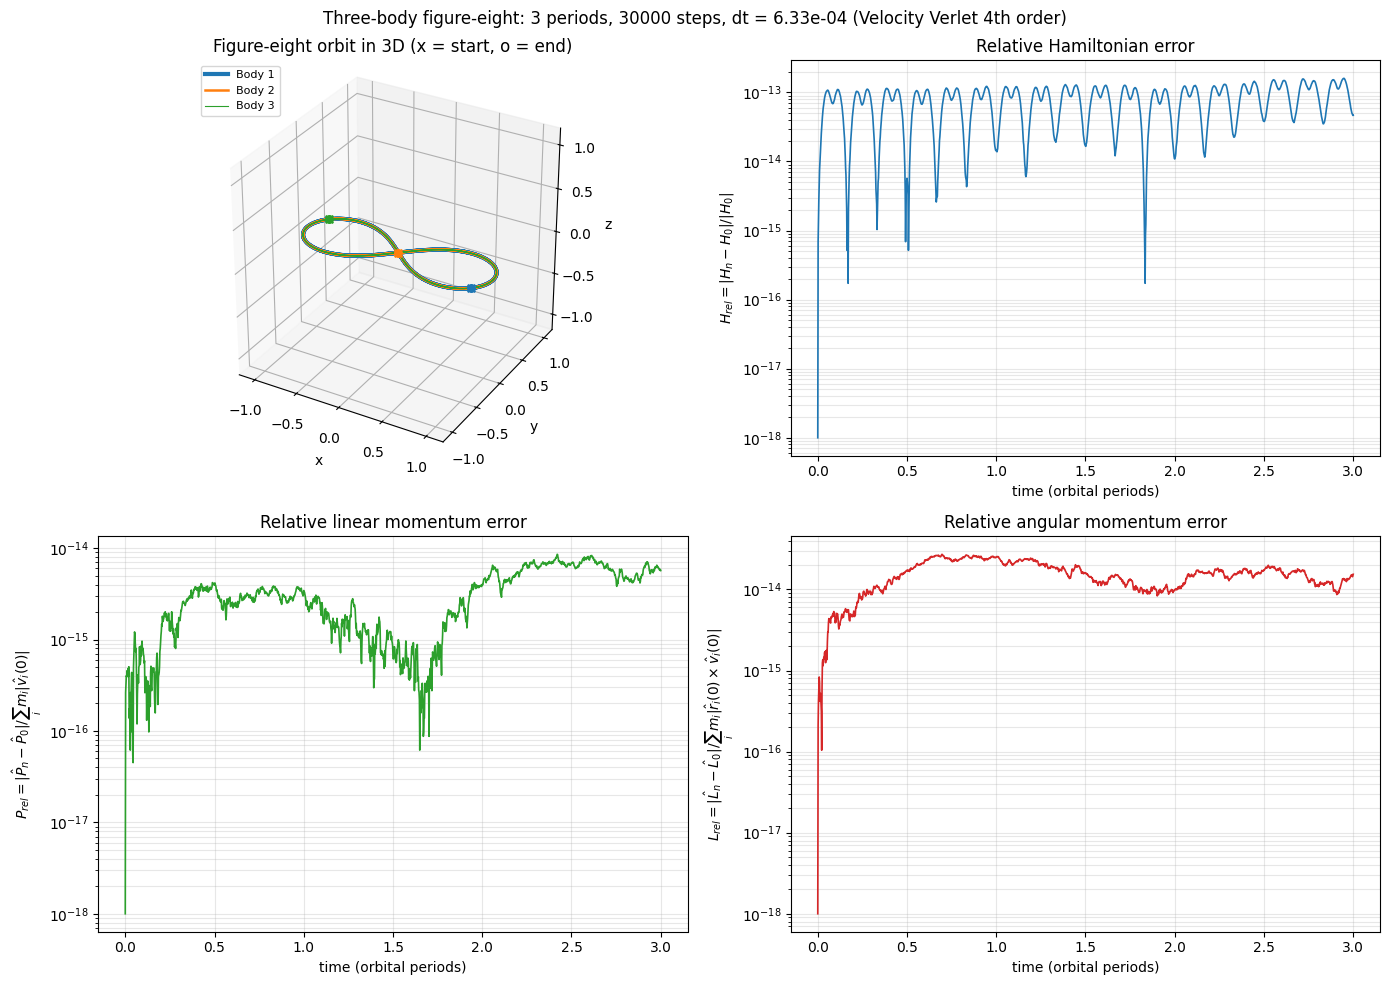

In [1]:
"""
Experiment 1: the three-body figure-eight choreography (28/10/26).

Purpose:
    The figure-eight is a periodic solution of the planar three-body problem in which
    three equal masses chase one another along a single closed curve shaped like the
    number eight. It was found numerically by Moore (1993) and its existence was proven
    by Chenciner & Montgomery (2000). Because the exact answer is known (the bodies must
    return to their starting positions after every period T), it is an ideal first
    validation test for the integrator: any drift away from the starting positions after
    a whole number of periods is a direct measure of the numerical error.

Setup:
    - three equal masses chasing each other along a single figure-eight curve
    - initial conditions from Simo's high-precision values, in natural units G = m = 1
    - no softening: the bodies never come close, and softening would perturb the orbit
    - integrated with run_vv_4 (Velocity Verlet 4th order)

Time control:
    - the total simulated time is a whole number of orbital periods
    - dt is dictated by the number of timesteps: dt = t_total / n_steps
    - frames are computed separately: one trajectory point is stored every
      steps_per_frame = n_steps / n_frames steps
Conservation tracking:
    The Hamiltonian H and the linear and angular momenta P and L are evaluated at every stored
    frame (conservation_state), and their relative errors H_rel, P_rel and L_rel are plotted
    together with the 3D orbit. The output is these four plots plus the closure error after the run.
"""


# A minimal body: mass, displacement, velocity and acceleration.
# The integrator (run_vv_4) and the force routine (acc) only ever access the
# attributes m, r, v and a, so any object that carries these four attributes
# can be simulated. All vectors are stored as 3-component NumPy arrays, so that
# the same code works for planar (z = 0) and fully three-dimensional problems.
class Body:
    def __init__(self, m, r, v):
        self.m = m      # mass (scalar)
        self.r = np.array(r, dtype=float)       # displacement vector (x, y, z)
        self.v = np.array(v, dtype=float)       # velocity vector (vx, vy, vz)
        self.a = np.zeros(3)        # acceleration vector, filled in by run_vv_4 on its first call


# Experiment parameters (natural units: G = 1, m = 1)
# The published figure-eight initial conditions are dimensionless: they assume G = 1
# and unit masses. Working in SI units would require rescaling every quantity, so the
# experiment is run directly in these natural units. Lengths, times and velocities
# printed below are therefore dimensionless as well.
G_nat = 1.0     # gravitational constant in natural units

# Plummer softening (Eq. 4) is switched off. The closest approach between any two
# bodies on the figure-eight is about 0.7 length units, so there is no risk of a
# division by zero, and any non-zero softening would alter the force law and hence
# destroy the periodicity that this experiment relies on.
e_soft = 0.0    # softening length (switched off, see above)

# Period of one full figure-eight orbit in natural units. After exactly one period
# every body returns to its own starting position. The value is only known to a
# finite number of digits, which sets a lower floor on the closure error below.
T_period = 6.32591398     # period of the figure-eight orbit (Simo's value, 9 significant digits)

# The three numbers below fully control the time discretisation:
#   n_periods – how long the simulation runs (t_total = n_periods * T_period)
#   n_steps – how finely that time is divided (this alone dictates dt)
#   n_frames – how many snapshots are stored for plotting (independent of dt)
# Increasing n_steps makes dt smaller and the result more accurate (the global error
# of the 4th-order scheme falls as dt^4) at a proportionally higher cost, while
# n_frames only changes the resolution of the plots and the memory used.
n_periods = 3   # number of full orbits to simulate
n_steps = 30000     # total number of timesteps (dictates dt)
n_frames = 1500     # number of stored trajectory points (independent of dt)

# Derived time quantities
t_total = n_periods * T_period      # total simulated time
dt = t_total / n_steps      # timestep implied by the chosen number of steps

# The integration is split into n_frames equal blocks of steps_per_frame steps each,
# and one snapshot is stored at the end of every block. For the blocks to add up to
# exactly n_steps, n_steps must be an integer multiple of n_frames; otherwise the run
# would stop short of (or overshoot) t_total and the closure test would be invalid.
assert n_steps % n_frames == 0, "n_steps must be divisible by n_frames"
steps_per_frame = n_steps // n_frames       # integration steps between two stored snapshots

# Initial conditions
# The configuration at t = 0 is symmetric:
#   – body 2 sits exactly at the crossing point (centre) of the eight
#   – bodies 1 and 3 sit at mirror-image positions, r3 = -r1
#   – bodies 1 and 3 share the same velocity, and body 2 moves with -2 times it
# These conditions give zero total momentum (m*v1 + m*v2 + m*v3 = 0), so the centre of
# mass stays fixed at the origin and no correction for drift is needed (unlike in a
# system with a randomly launched star). All z-components are zero, so the motion
# remains in the x-y plane for the entire run.
r1 = [0.97000436, -0.24308753, 0.0]     # displacement of body 1 (body 3 is its mirror image)
v2 = [-0.93240737, -0.86473146, 0.0]    # velocity of the central body 2
v13 = [-0.5 * v2[0], -0.5 * v2[1], 0.0]     # v1 = v3 = -v2 / 2, so the total momentum is zero

# The three bodies, each with unit mass
bodies = [
    Body(1.0, r1, v13),     # body 1: right-hand lobe
    Body(1.0, [0.0, 0.0, 0.0], v2),     # body 2: centre of the eight
    Body(1.0, [-r1[0], -r1[1], 0.0], v13),      # body 3: left-hand lobe
]

# Copies of the starting positions, kept for the closure test at the end of the run.
# .copy() is essential: without it r_start would refer to the same arrays that the
# integrator overwrites, and the closure error would always read zero.
r_start = [b.r.copy() for b in bodies]

# Summary of the time discretisation actually used
print(f"t_total = {t_total:.4f} ({n_periods} periods), n_steps = {n_steps}, dt = {dt:.3e}")
print(f"n_frames = {n_frames}, steps_per_frame = {steps_per_frame}")

# Conservation references
# The state at t = 0 is the reference for every relative error. P_0 and L_0 are exactly
# zero for this configuration (see the initial-conditions comment above), so p_rel and
# l_rel fall back on the characteristic size of the individual momenta, p_scale and l_scale.
H_0, P_0, L_0 = conservation_state(bodies, G_nat, e_soft)
P_scale, L_scale = p_scale(bodies), l_scale(bodies)
print(f"H_0 = {H_0:.6f}, |P_0| = {np.linalg.norm(P_0):.1e}, |L_0| = {np.linalg.norm(L_0):.1e}")

# Simulation
# trajectories[k] is the list of stored displacements of body k. It starts with the
# initial position, so after the loop each list holds n_frames + 1 points (t = 0 plus
# one point per block). run_vv_4 advances the bodies in place by steps_per_frame steps
# of size dt; after each call the new positions are copied into the record and the
# conserved quantities are measured on the freshly updated bodies.
# NB: run_vv_4 recomputes the accelerations at the start of every call. This costs one
# extra force evaluation per frame but does not change the result, because the
# accelerations depend only on the current positions.
trajectories = [[b.r.copy()] for b in bodies]
h_err, p_err, l_err = [0.0], [0.0], [0.0]       # relative errors at t = 0 are zero by definition
for _ in range(n_frames):
    run_vv_4(bodies, G_nat, e_soft, dt, steps_per_frame)
    for k, b in enumerate(bodies):
        trajectories[k].append(b.r.copy())

    H_n, P_n, L_n = conservation_state(bodies, G_nat, e_soft)
    h_err.append(h_rel(H_0, H_n))
    p_err.append(p_rel(P_0, P_n, P_scale))
    l_err.append(l_rel(L_0, L_n, L_scale))

# Convert the nested lists into a single array for convenient slicing:
#   axis 0 – body index k, axis 1 -> frame index, axis 2 -> coordinate (x, y, z)
trajectories = np.array(trajectories)       # shape: (N bodies, n_frames + 1, 3)
h_err, p_err, l_err = np.array(h_err), np.array(p_err), np.array(l_err)
t_frames = np.arange(n_frames + 1) * steps_per_frame * dt / T_period    # time in orbital periods

# Validation
# Closure check: after a whole number of periods every body should be back where it
# started. The distance |r(t_total) - r(0)| therefore measures the accumulated error.
# It contains two contributions: the integration error of the scheme (which shrinks as
# dt^4 when n_steps is increased) and the finite precision of T_period and of the
# initial conditions (which does not shrink with dt). Once the error stops decreasing
# when n_steps is raised, the second contribution has become dominant.
for k, b in enumerate(bodies):
    print(f"body {k + 1}: closure error |r(T) - r(0)| = {np.linalg.norm(b.r - r_start[k]):.3e}")

# Planarity check: with all z-components initially zero, the accelerations of Eq. (4)
# have no z-component either, so z must remain exactly zero for the whole run.
print(f"max |z| over the run = {np.abs(trajectories[:, :, 2]).max():.3e} (the orbit is planar)")

# Conservation summary
print(f"max H_rel = {h_err.max():.3e}, max P_rel = {p_err.max():.3e}, max L_rel = {l_err.max():.3e}")

# Plots: 3D orbit + the three relative conservation errors
colours = plt.cm.tab10(np.arange(3))        # one distinct colour per body

# All three bodies travel along the very same curve, so lines of equal width would hide
# one another. Drawing them with decreasing widths (body 1 widest, body 3 thinnest)
# keeps every trajectory visible as a coloured band inside the previous one.
line_widths = [3.0, 1.8, 0.8]
fig = plt.figure(figsize=(14, 10))

# 3D view
# The orbit is planar, so this view shows the eight lying flat at z = 0. Any spurious
# out-of-plane motion would be visible here. The end markers (o) should lie on top of
# the start markers (x) because the run covers a whole number of periods.
ax3d = fig.add_subplot(2, 2, 1, projection="3d")
for k in range(len(bodies)):
    x, y, z = trajectories[k].T     # transpose (frames, 3) three coordinate arrays
    ax3d.plot(x, y, z, color=colours[k], lw=line_widths[k], label=f"Body {k + 1}")
    ax3d.scatter(x[0], y[0], z[0], color=colours[k], marker="x", s=30)     # starting position
    ax3d.scatter(x[-1], y[-1], z[-1], color=colours[k], s=30)       # final position

# Use the same limits on all three axes and a cubic box, so that lengths in different
# directions are directly comparable and the orbit is not visually distorted.
lim = 1.1 * np.abs(trajectories).max()      # 10% margin around the furthest point reached
ax3d.set_xlim(-lim, lim)
ax3d.set_ylim(-lim, lim)
ax3d.set_zlim(-lim, lim)
ax3d.set_box_aspect((1, 1, 1))
ax3d.set_xlabel("x")
ax3d.set_ylabel("y")
ax3d.set_zlabel("z")
ax3d.set_title("Figure-eight orbit in 3D (x = start, o = end)")
ax3d.legend(fontsize=8, loc="upper left")

# Relative conservation errors (logarithmic y-axis, time measured in orbital periods).
# The floor of 1e-18 only keeps exact zeros (e.g. at t = 0) drawable on a log axis.
floor = 1e-18
panels = [
    (h_err, r"$H_{rel}=|H_n-H_0|/|H_0|$", "Relative Hamiltonian error", "tab:blue"),
    (p_err, r"$P_{rel}=|\hat{P}_n-\hat{P}_0|/\sum_i m_i|\hat{v}_i(0)|$", "Relative linear momentum error", "tab:green"),
    (l_err, r"$L_{rel}=|\hat{L}_n-\hat{L}_0|/\sum_i m_i|\hat{r}_i(0)\times\hat{v}_i(0)|$", "Relative angular momentum error", "tab:red"),
]
for idx, (err, ylabel, title, colour) in enumerate(panels):
    ax = fig.add_subplot(2, 2, idx + 2)
    ax.semilogy(t_frames, np.maximum(err, floor), color=colour, lw=1.2)
    ax.set_xlabel("time (orbital periods)")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(alpha=0.3, which="both")

fig.suptitle(f"Three-body figure-eight: {n_periods} periods, {n_steps} steps, "
             f"dt = {dt:.2e} (Velocity Verlet 4th order)")
plt.tight_layout()
plt.show()